This notebook tries to look at the various costs when using a qutrit (or ququart) whose gaps have various "relationships" to the qubit's gaps, and seeing how that compares

In [1]:
from joblib import Parallel, delayed

from tqdm import tqdm
import numpy as np
import experimental as ex

temp = 10
alpha_space = np.linspace(0.501, 0.999, 500)

def scan_experimental_bit(alpha_goal):
    energies = ex.scan_gaps(2, alpha_goal, iters=10000, gap_min=0.0001, gap_max=1000, temp=temp)
    _, e_values, _ = zip(*energies)
    min_gaps = energies[np.argmin(e_values)]
    return alpha_goal, *min_gaps

In [2]:

# ~1 min on 7800X3D (16 cores), so 8 iterations/sec
best_gaps_exp_bit = Parallel(n_jobs=-2)(
    delayed(scan_experimental_bit)(alpha) for alpha in tqdm(alpha_space, leave=True)
)

100%|██████████| 500/500 [00:58<00:00,  8.52it/s]


In [8]:
equal_gap_qutrit = [ex.get_step_data_gaps([gap, gap], alpha, temp=temp) for alpha, gap, _, _ in best_gaps_exp_bit]
zero_last_gap_qutrit = [ex.get_step_data_gaps([gap, 0], alpha, temp=temp) for alpha, gap, _, _ in best_gaps_exp_bit]
inf_last_gap_qutrit = [ex.get_step_data_gaps([gap, 1e20], alpha, temp=temp) for alpha, gap, _, _ in best_gaps_exp_bit]
zero_first_gap_qutrit = [ex.get_step_data_gaps([0, gap], alpha, temp=temp) for alpha, gap, _, _ in best_gaps_exp_bit]
halved_gap_qutrit = [ex.get_step_data_gaps([gap/2, gap/2], alpha, temp=temp) for alpha, gap, _, _ in best_gaps_exp_bit]
tq_gap_qutrit = [ex.get_step_data_gaps([gap*3/4, gap*3/4], alpha, temp=temp) for alpha, gap, _, _ in best_gaps_exp_bit]
and_half_qutrit = [ex.get_step_data_gaps([gap, gap/2], alpha, temp=temp) for alpha, gap, _, _ in best_gaps_exp_bit]
half_and_qutrit = [ex.get_step_data_gaps([gap/2, gap], alpha, temp=temp) for alpha, gap, _, _ in best_gaps_exp_bit]
geom_split_qutrit = [ex.get_step_data_gaps([2*gap/3, gap/3], alpha, temp=temp) for alpha, gap, _, _ in best_gaps_exp_bit]

thirds_ququart = [ex.get_step_data_gaps([gap/3, gap/3, gap/3], alpha, temp=temp) for alpha, gap, _, _ in best_gaps_exp_bit]
geom_split_ququart = [ex.get_step_data_gaps([4*gap/7, 2*gap/7, gap/7], alpha, temp=temp) for alpha, gap, _, _ in best_gaps_exp_bit]

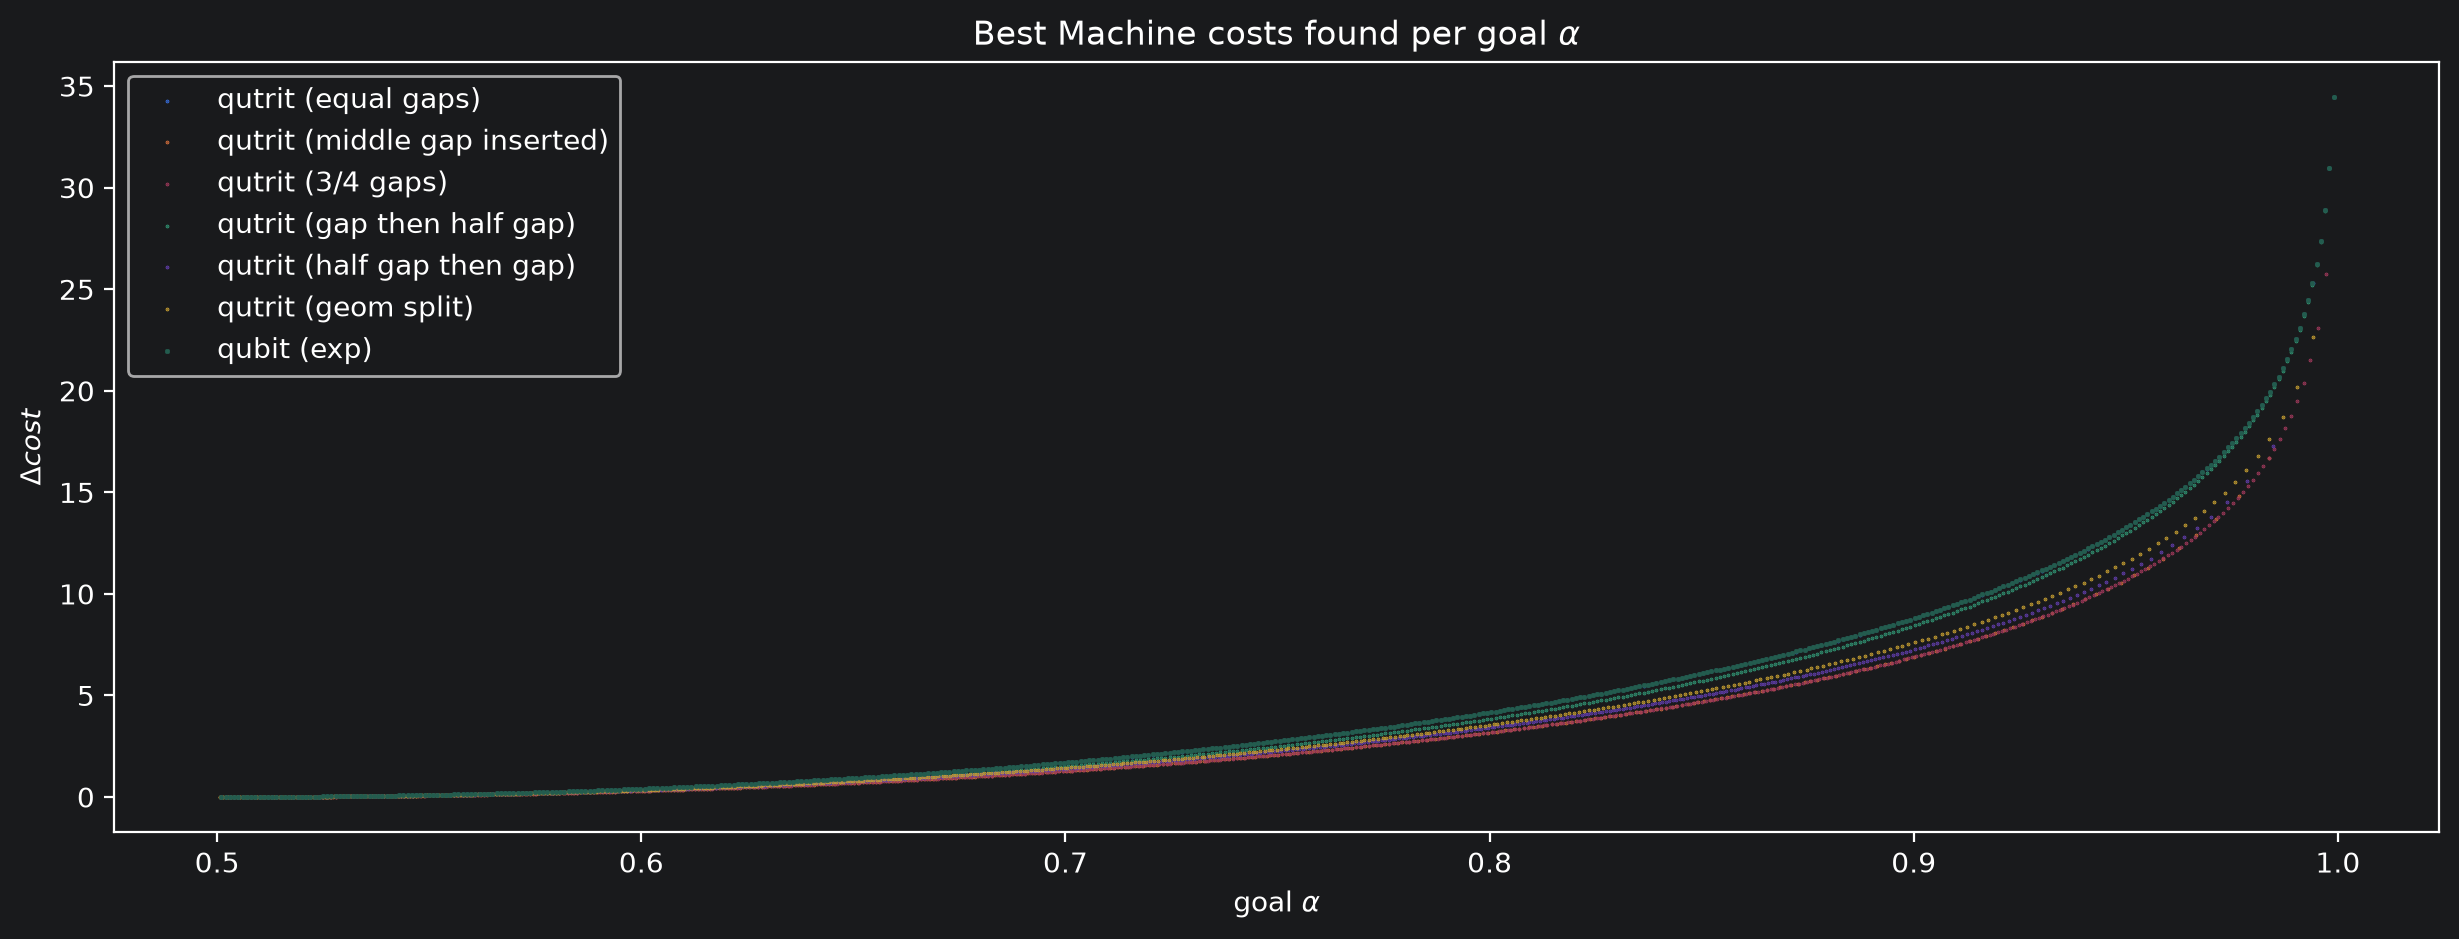

In [10]:
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

alphas_exp2, _, energies_exp2, _ = zip(*best_gaps_exp_bit)

alphas_equal, energies_equal, _ = zip(*equal_gap_qutrit)
alphas_zl, energies_zl, _ = zip(*zero_last_gap_qutrit)
alphas_zf, energies_zf, _ = zip(*zero_first_gap_qutrit)
alphas_il, energies_il, _ = zip(*inf_last_gap_qutrit)
alphas_half, energies_half, _ = zip(*halved_gap_qutrit)
alphas_tq, energies_tq, _ = zip(*tq_gap_qutrit)
alphas_andhalf, energies_andhalf, _ = zip(*and_half_qutrit)
alphas_halfand, energies_halfand, _ = zip(*half_and_qutrit)
alphas_geom_3, energies_geom_3, _ = zip(*geom_split_qutrit)

alphas_thirds, energies_thirds, _ = zip(*thirds_ququart)
alphas_geom_4, energies_geom_4, _ = zip(*geom_split_ququart)

fig = figure(figsize=(15,5), dpi=200)
ax = plt.gca()
#ax.set_yscale('log')

dotsize = 100 / fig.dpi

ax.scatter(alphas_equal, energies_equal, marker='.', label=r"qutrit (equal gaps)", s=dotsize)
#ax.scatter(alphas_zl, energies_zl, marker='.', label=r"qutrit (last gap=0)")
#ax.scatter(alphas_zf, energies_zf, marker='.', label=r"qutrit (first gap=0)")
#ax.scatter(alphas_il, energies_il, marker='.', label=r"qutrit (last gap=infinite)", s=dotsize)
ax.scatter(alphas_half, energies_half, marker='.', label=r"qutrit (middle gap inserted)", s=dotsize)
ax.scatter(alphas_tq, energies_tq, marker='.', label=r"qutrit (3/4 gaps)", s=dotsize)
ax.scatter(alphas_andhalf, energies_andhalf, marker='.', label=r"qutrit (gap then half gap)", s=dotsize)
ax.scatter(alphas_halfand, energies_halfand, marker='.', label=r"qutrit (half gap then gap)", s=dotsize)
ax.scatter(alphas_geom_3, energies_geom_3, marker='.', label=r"qutrit (geom split)", s=dotsize)


#ax.scatter(alphas_halfand, energies_halfand, marker='+', label=r"ququart (split into thirds)", s=dotsize)
#ax.scatter(alphas_geom_4, energies_geom_4, marker='+', label=r"ququart (geom split)", s=dotsize)


ax.scatter(alphas_exp2, energies_exp2, marker='s', label=r"qubit (exp)", s=dotsize)

ax.set_ylabel(r"$\Delta cost$")
ax.set_xlabel(r"goal $\alpha$")
plt.title(r'Best Machine costs found per goal $\alpha$')
ax.legend()

plt.show()